In [1]:
# Helper to visualize results
from viz_helper import render_geom

In [2]:
from arcgis_geometry import Geometry as rust_geom

#### Access Portal Data

In [4]:
from arcgis.gis import GIS
gis = GIS(profile="your_enterprise_profile")
print(gis)

rust_simple_features = gis.content.get("f639df1dd17448baa1481ee72e1054fe")
grid_layer = rust_simple_features.layers[1]

my_locations_layer = rust_simple_features.layers[0]
my_locations_layer

GIS @ https://pythonapitestnb.dev.geocloud.com/portal version:[2025, 2]


<FeatureLayer url:"https://pythonapitestnb.dev.geocloud.com/server/rest/services/Hosted/SimpleFLC/FeatureServer/0">

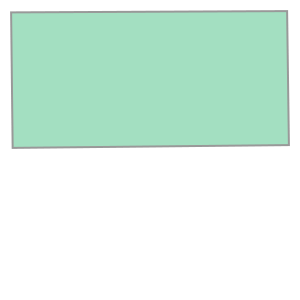

In [6]:
grid_fs = grid_layer.query("Name = 'Square4'", as_df=True)
grid_square = grid_fs["SHAPE"][0]
grid_square_rust = rust_geom(grid_square)
render_geom(grid_square_rust, "polygon")

### Boundary

`<Polygon>.boundary()`

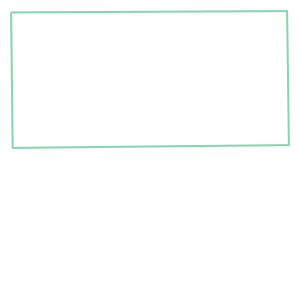

In [8]:
bndry = grid_square_rust.boundary()
render_geom(bndry, "polyline")

### Point Along Line

`<Polyline>.with_point_along(distance)`

In [15]:
point_along = bndry.with_point_along(5280)
print(type(point_along))

<class 'builtins.Point'>


In [32]:
map1 = gis.map("Yorba Linda, CA")
map1.content.draw(render_geom(bndry, "polyline"))
map1.content.draw(render_geom(point_along, "point"))
map1

Map()

### Contains

`arcgis.geometry.contains(geom1, geom2)` Does geometry 1 contain geometry 2?

`geometry1.contains(geometry2)`

In [33]:
buff_square = grid_square_rust.buffer(1000)
point_along.within(buff_square)

True

In [46]:
grid_fs = grid_layer.query("Name = 'Square1'", as_df=True)
grid_square_1 = rust_geom(grid_fs["SHAPE"][0])

my_locations_df = my_locations_layer.query("1=1", as_df=True)
locs = list(my_locations_df["SHAPE"])
rust_loc_points = [rust_geom(i) for i in locs]

rust_loc_points

[{"spatialReference": {"wkid":103008,"latestWkid":6426}, "x": 6071797.470455393, "y": 2270259.3892540634},
 {"spatialReference": {"wkid":103008,"latestWkid":6426}, "x": 6068475.775655225, "y": 2264596.024596557},
 {"spatialReference": {"wkid":103008,"latestWkid":6426}, "x": 6084511.562809303, "y": 2262992.4608745575},
 {"spatialReference": {"wkid":103008,"latestWkid":6426}, "x": 6078330.690656632, "y": 2268845.226071894}]

In [56]:
map2 = gis.map("Yorba Linda, CA")
map2.content.draw(render_geom(grid_square_1, "polygon"))
for pt in rust_loc_points:
    if grid_square_1.contains(pt):
        map2.content.draw(render_geom(pt, "point"))
map2

Map()

### Within

`arcgis.geometry.within(geom1, geom2)` Is geometry 1 within geometry 2?

`geometry1.within(geometry2)`

In [58]:
for pt in rust_loc_points:
    print(pt.within(grid_square_1))

True
True
False
False
